In [1]:
import os, shutil
BASE = "/content/simuteh-2330511010"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)

from google.colab import files
up = files.upload()   # pilih buat_dataset_sintetis.py dan utils_cv.py dari folder src di laptopmu
for n in up:
    shutil.move(n, f"{BASE}/src/{n}")

os.chdir(BASE)
!grep "SEED =" src/buat_dataset_sintetis.py
!python src/buat_dataset_sintetis.py
!ls data/sintetis/citra | wc -l
os.chdir(f"{BASE}/notebook")
print("Sekarang di:", os.getcwd())

Saving buat_dataset_sintetis.py to buat_dataset_sintetis.py
Saving utils_cv.py to utils_cv.py
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.
SEED = 1010          # 4 digit terakhir NIM 2330511010
Selesai: 60 citra tersimpan di data/sintetis
60
Sekarang di: /content/simuteh-2330511010/notebook


In [2]:
import sys
sys.path.append("../src")
import cv2, numpy as np, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

KB kanal B   : 1.98
KB kanal G   : 1.88
KB kanal R   : 7.99
KB kanal Gray: 4.87
KB kanal H   : 4.74
KB kanal S   : 0.49
KB kanal V   : 3.23


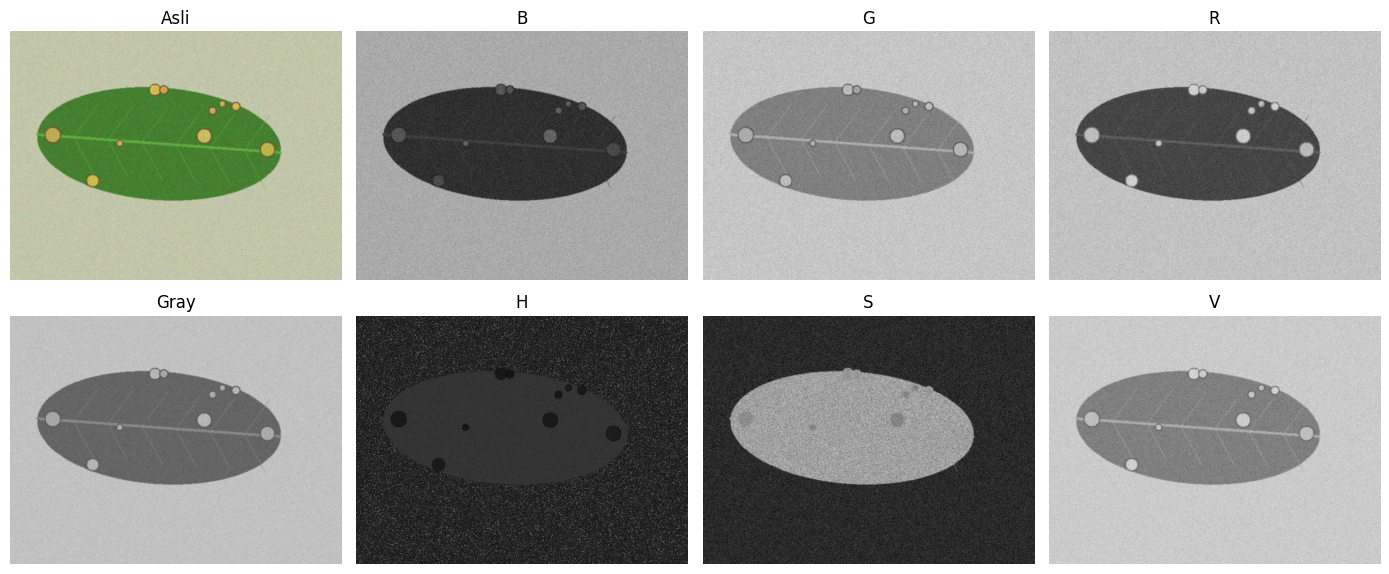

In [6]:
# Kode 2.1 Pemisahan kanal dan Kontras Bercak
nama = "teh_041.png" # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", dpi=120)   # <-- baris baru
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [7]:
# Kode 2.2 Sampling dan kuantisasi
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")
# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=6.19
fx=0.2: ukuran (96, 128), KB=5.47
fx=0.1: ukuran (48, 64), KB=3.82
fx=0.05: ukuran (24, 32), KB=1.72
k=1: 2 level, KB=4.40
k=2: 3 level, KB=4.59
k=3: 6 level, KB=3.07
k=4: 11 level, KB=4.44
k=8: 161 level, KB=4.87


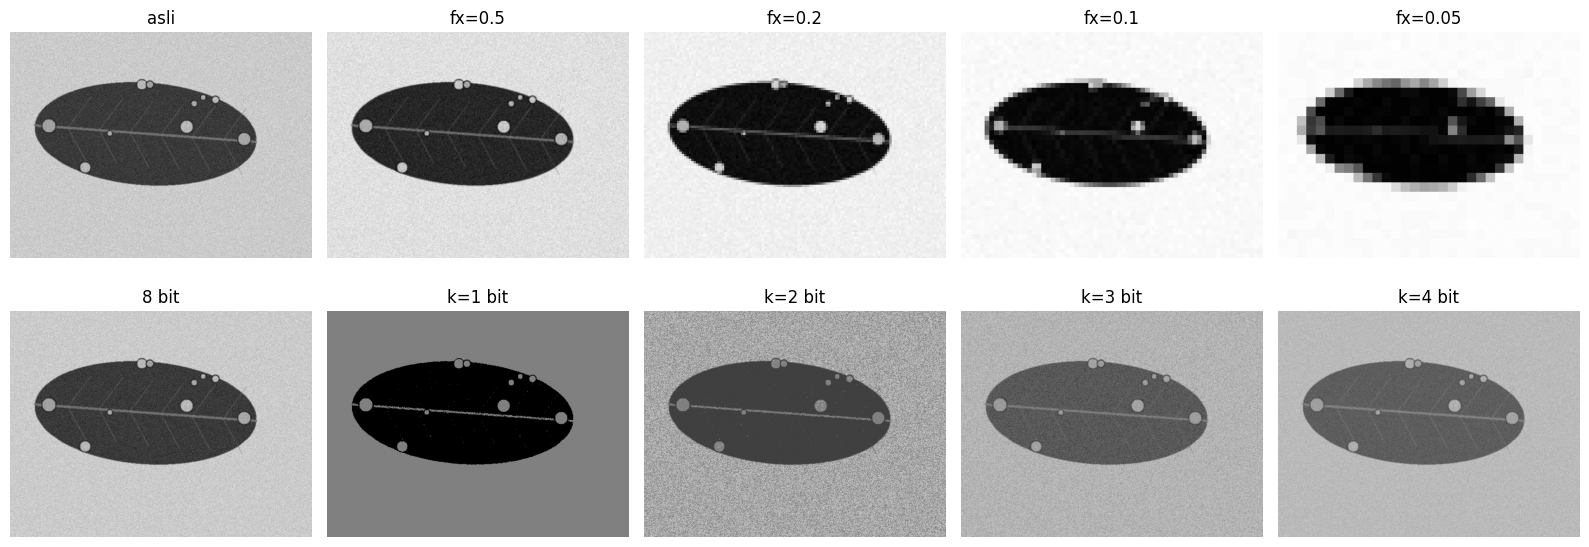

In [8]:
# Menampilkan Hasil citra
fig, ax = plt.subplots(2, 5, figsize=(16, 6))
ax[0, 0].imshow(gray, cmap="gray"); ax[0, 0].set_title("asli")
for i, fx in enumerate([0.5, 0.2, 0.1, 0.05]):
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    ax[0, i+1].imshow(besar, cmap="gray"); ax[0, i+1].set_title(f"fx={fx}")
ax[1, 0].imshow(gray, cmap="gray"); ax[1, 0].set_title("8 bit")
for i, k in enumerate([1, 2, 3, 4]):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    ax[1, i+1].imshow(kuant, cmap="gray", vmin=0, vmax=255); ax[1, i+1].set_title(f"k={k} bit")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b2_sampling_kuantisasi.png", dpi=110)

In [9]:
# ===== Langkah 2.5 | Kode 2.3: Rerata KB per kanal dan per kondisi (kelas berat) -> Tabel 8 =====
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        0.75  0.67  5.79  1.87  4.78  0.40  1.20
gelap           1.21  0.88  9.06  3.82  5.33  1.12  2.45
kontras_rendah  0.86  0.53  3.74  2.21  1.70  0.14  1.54
normal          2.11  1.24  8.42  4.66  5.66  1.15  2.74
terang          2.70  0.71  7.60  4.12  6.06  1.39  1.99


In [10]:
# ===== Langkah 2.6 | Rerata KB per kanal dan kondisi (kelas RINGAN) =====
baris = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
urutan = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
tabel_ringan = pd.DataFrame(baris).groupby("kondisi").mean().round(2).loc[urutan]
print(tabel_ringan)
tabel_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          0.90  0.89  8.10  3.12  7.11  0.70  1.37
gelap           1.17  1.04  8.85  2.54  6.66  1.50  1.66
terang          1.26  0.15  5.59  2.54  4.47  0.75  1.30
kontras_rendah  0.53  0.36  3.64  1.58  2.36  0.38  0.92
bayangan        1.11  0.32  4.41  0.94  4.55  1.12  0.42


Kanal terbaik: R


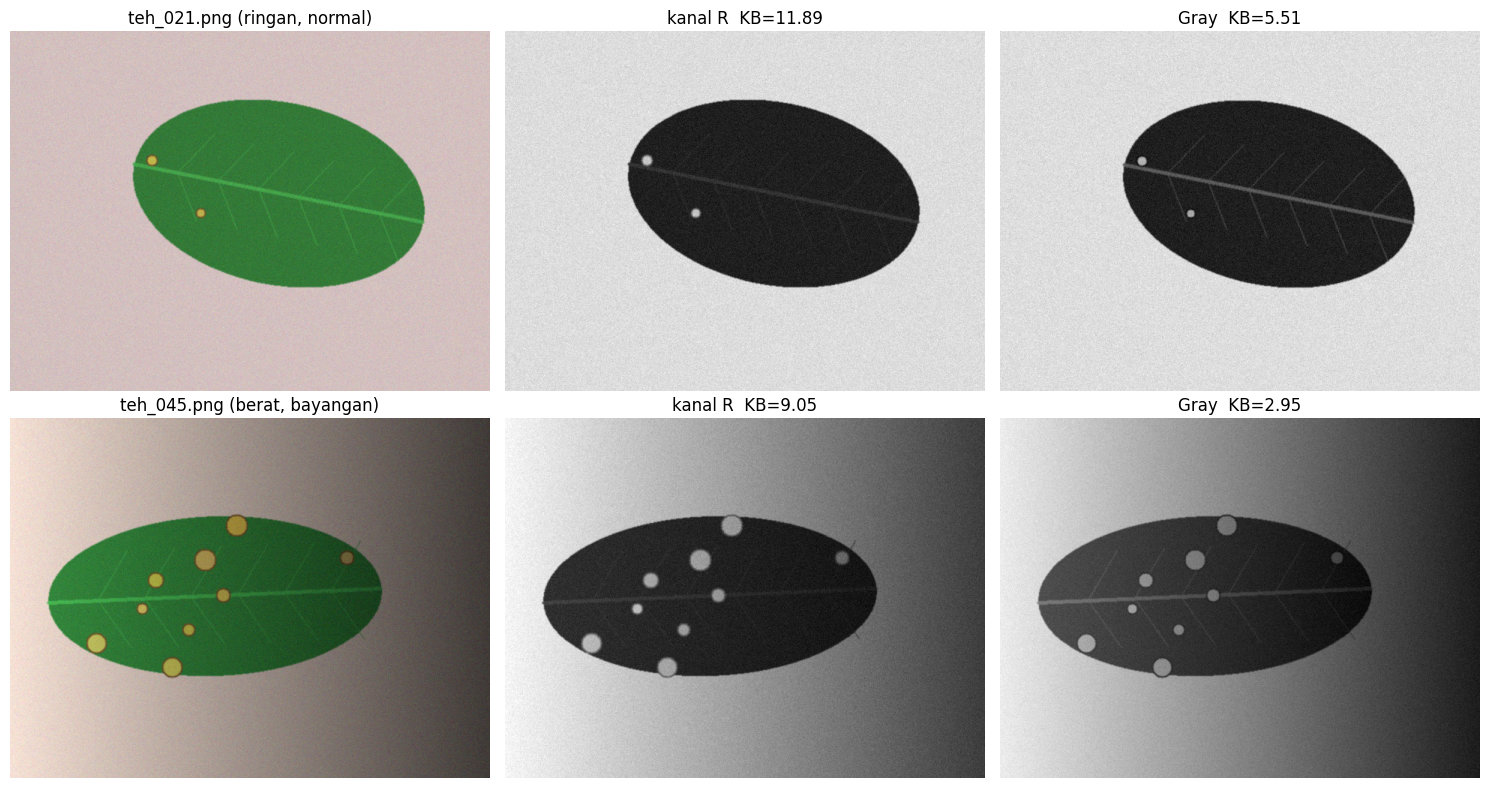

In [11]:
# ===== Langkah 2.6 | Panel kanal terbaik: teh_021 (ringan, normal) dan teh_045 (berat, bayangan) =====
terbaik = tabel_kb.mean().idxmax()      # kanal dengan rerata KB tertinggi (kelas berat)
print("Kanal terbaik:", terbaik)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, (nm, ket) in enumerate([("teh_021.png", "ringan, normal"), ("teh_045.png", "berat, bayangan")]):
    im = baca(f"../data/sintetis/citra/{nm}"); kn = semua_kanal(im)
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    ax[i, 0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title(f"{nm} ({ket})")
    ax[i, 1].imshow(kn[terbaik], cmap="gray")
    ax[i, 1].set_title(f"kanal {terbaik}  KB={kontras_bercak(kn[terbaik], m_d, m_b):.2f}")
    ax[i, 2].imshow(kn["Gray"], cmap="gray")
    ax[i, 2].set_title(f"Gray  KB={kontras_bercak(kn['Gray'], m_d, m_b):.2f}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b2_kanal_terbaik.png", dpi=110)